<h1>Section 3 – Unsupervised learning – clustering</h1>
In this unsupervised learning task, the objective is to cluster Reddit comments based on the words used
within the comments in them. The aim is to identify patterns and group comments with similar words
together.

<h2>Kmeans</h2>

In [12]:
!pip install nltk

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [14]:
data=pd.read_csv("data_unsupervised.csv", encoding="utf8")

data['body'] = data['body'].str.lower()#to lowercase
data['body'] = data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
data['body'] = data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace

#data = data[~(data['body'].str.len() < 10)] #drop comments with less than 10 characters
#data = data[~(data['body'].str.len() > 500)] #drop comments with more than 500 characters

data=data.dropna()
data=data.drop_duplicates()

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

word_counts = data['body'].str.split().explode().value_counts()    
words_once = set(word_counts[word_counts == 1].index)#words that appear only once
most_freq_words = set(word_counts.nlargest(100).index)#most common words treated as stop words
remove_words = words_once | most_freq_words

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments
data = data.drop_duplicates(subset=['body'])
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(data['body'])

In [15]:
from sklearn.preprocessing import MaxAbsScaler
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=1000)
X = svd.fit_transform(X)
print("Explained variance by SVD:", svd.explained_variance_ratio_.sum())

X = MaxAbsScaler().fit_transform(X)
X=X*5

Explained variance by SVD: 0.6728987092015362


silhouette score computed:  0.2212101710751088
silhouette score computed:  0.23581941607060045
silhouette score computed:  0.24581784221562794
silhouette score computed:  0.18106737613405835
silhouette score computed:  0.22977897766892807
silhouette score computed:  0.1625772372076699
silhouette score computed:  0.15660116383460926
silhouette score computed:  0.15219704727736857
silhouette score computed:  0.11906575574535114
silhouette score computed:  0.10687555295804163
silhouette score computed:  0.06512030018887249
silhouette score computed:  0.0417091534315829
silhouette score computed:  0.1161308570060027
silhouette score computed:  0.10201040900995234
silhouette score computed:  0.06595320933540132


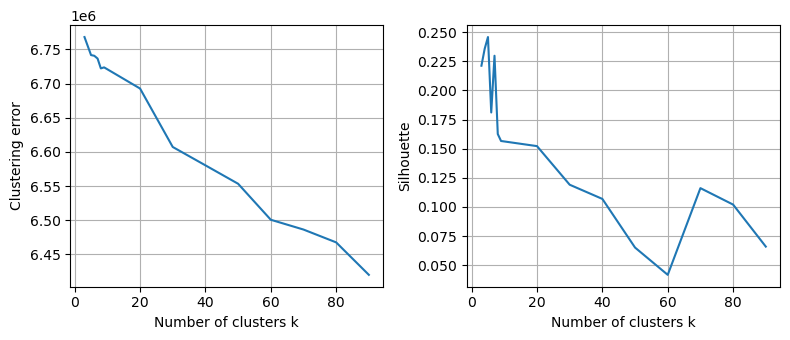

In [16]:
n_clusters=2
kmeans = KMeans(
    n_clusters, #will be choosen later
    init='random', #centroids are initialized randomly TOO SLOW
    #init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
    random_state=None, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300
    )
clustering_results = []

k_values=pd.concat([pd.Series(range(3, 10, 1)),pd.Series(range(20, 100, 10))])
for k in k_values:
    clustering_results.append(KMeans(n_clusters=k).fit(X))
    #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

n_sample=10000
silhouetteScores = []
for result in clustering_results:
    try:
        silhouetteScores.append(silhouette_score(X, result.labels_, sample_size=n_sample))
        print("silhouette score computed: ", silhouetteScores[-1])
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

# Plotting the results
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))
axs[0].plot(
    [k for k in k_values], 
    [result.inertia_ for result in clustering_results]
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()
axs[1].plot(
    [k for k in k_values], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.tight_layout()
plt.show()

In [17]:
numberOfChoosenClusters=3
indexOfChoosenCluster=k_values[k_values==numberOfChoosenClusters].index[0]

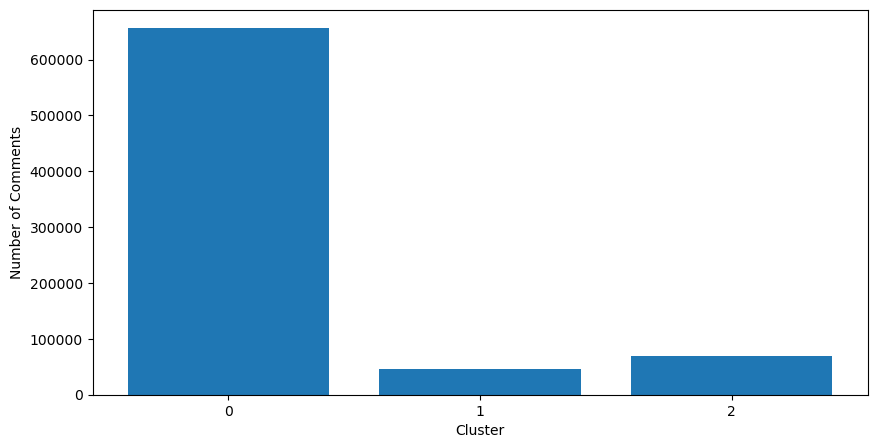

Cluster sizes: 0    656389
2     69894
1     45162
Name: count, dtype: int64


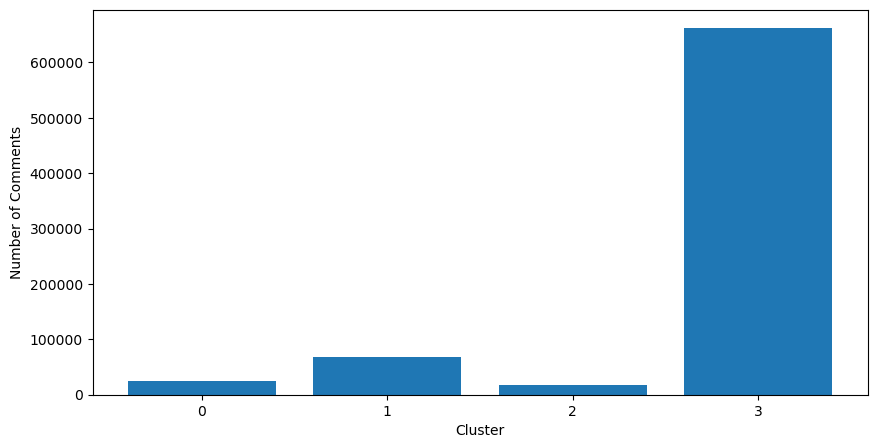

Cluster sizes: 3    661887
1     67985
0     24663
2     16910
Name: count, dtype: int64


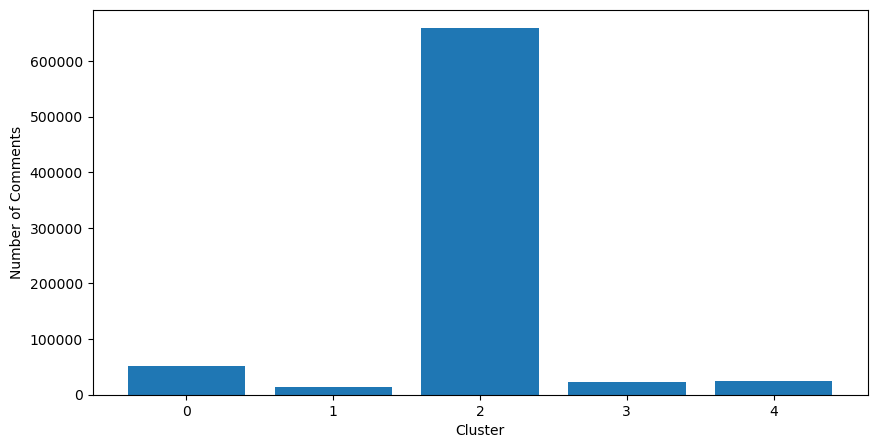

Cluster sizes: 2    659184
0     50884
4     23941
3     22944
1     14492
Name: count, dtype: int64


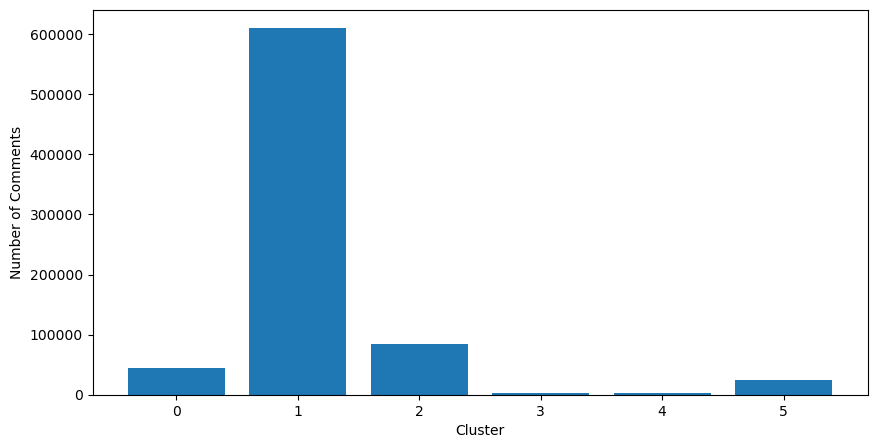

Cluster sizes: 1    610296
2     85244
0     45074
5     24111
4      3461
3      3259
Name: count, dtype: int64


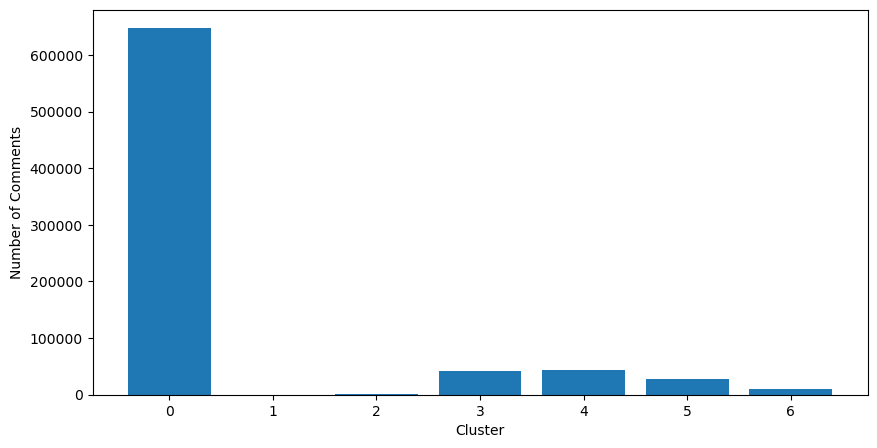

Cluster sizes: 0    647323
4     43806
3     41941
5     27731
6      9787
2       856
1         1
Name: count, dtype: int64


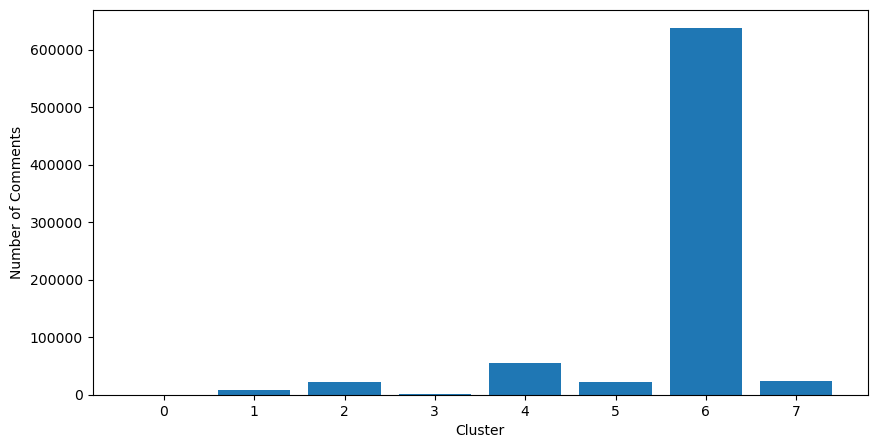

Cluster sizes: 6    637361
4     54713
7     23741
2     22819
5     22099
1      8647
3      1991
0        74
Name: count, dtype: int64


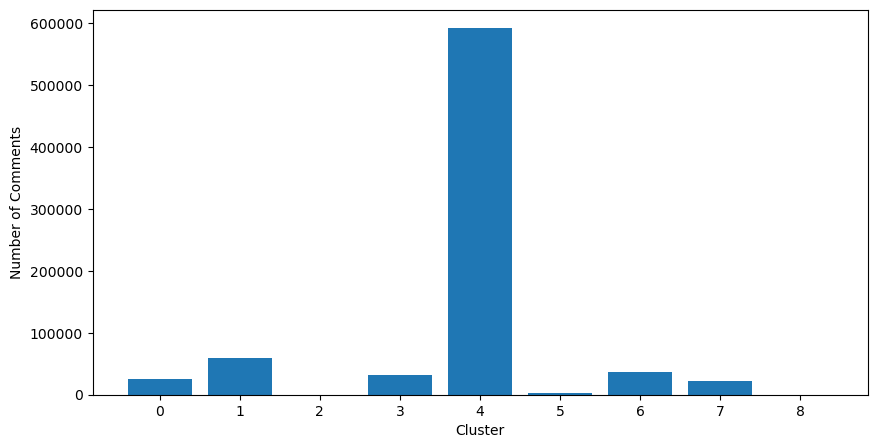

Cluster sizes: 4    592583
1     58917
6     36457
3     32077
0     24923
7     22810
5      3446
2       231
8         1
Name: count, dtype: int64


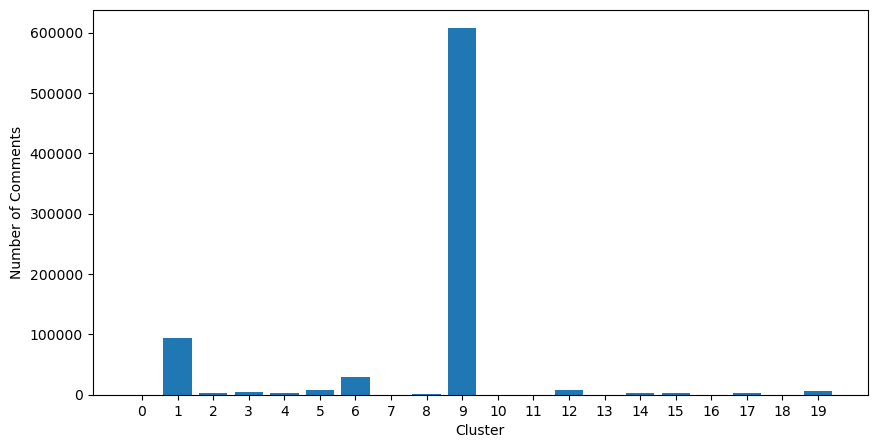

Cluster sizes: 9     607707
1      93592
6      29079
12      7874
5       7047
19      5774
3       3954
17      3240
15      3105
2       3027
4       2484
14      2252
8       1976
0        229
7         89
11         7
16         3
18         3
10         2
13         1
Name: count, dtype: int64


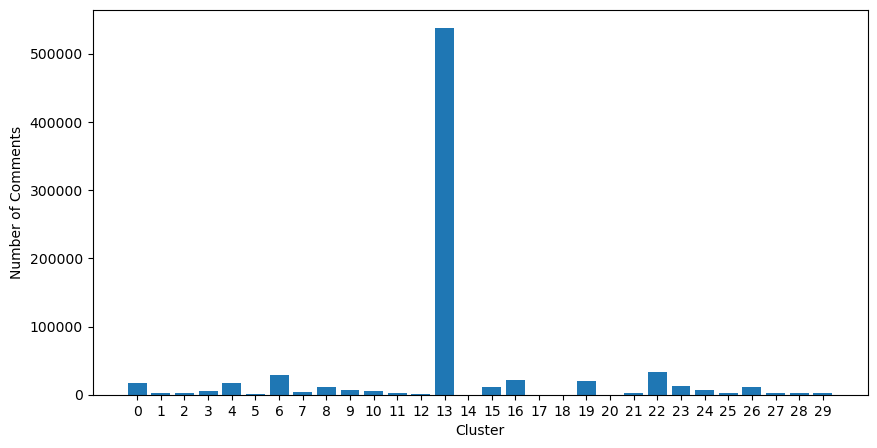

Cluster sizes: 13    537481
22     32981
6      28968
16     21512
19     20619
0      17100
4      16936
23     13136
26     11002
8      10639
15     10611
24      7522
9       7064
3       5239
10      4785
7       3387
29      3164
2       2708
25      2660
21      2439
27      2423
28      2101
1       1996
11      1882
12      1329
5        537
17       319
14       317
20       303
18       285
Name: count, dtype: int64


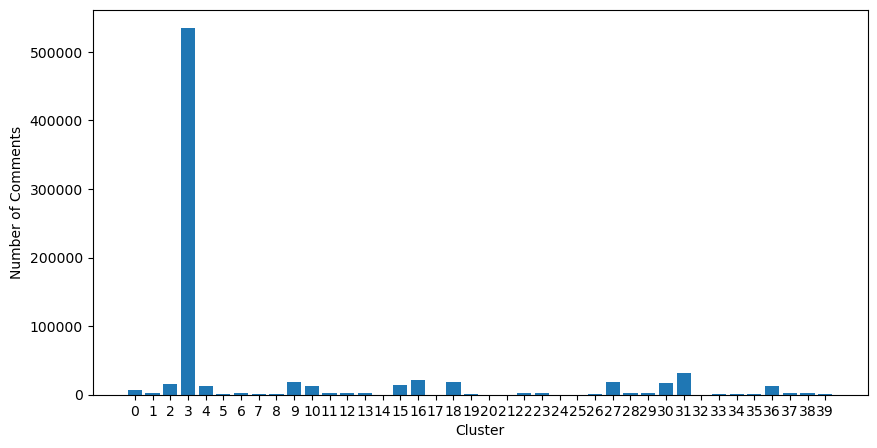

Cluster sizes: 3     534776
31     31994
16     21499
9      19232
27     19148
18     18457
30     17287
2      15154
15     13475
10     13049
4      12897
36     12335
0       6936
38      3056
29      3024
22      2937
11      2501
6       2369
28      2367
23      2248
37      1989
1       1970
12      1853
13      1827
39      1769
35      1743
5       1479
19       941
26       607
34       502
8        448
33       381
7        330
21       314
32       313
14       226
25         5
17         5
20         1
24         1
Name: count, dtype: int64


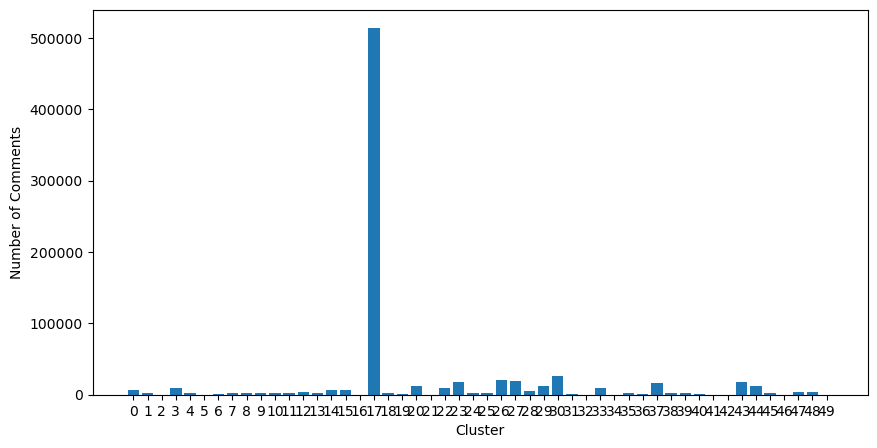

Cluster sizes: 17    513782
30     26370
26     20113
27     19234
43     17790
23     17206
37     16274
20     12397
29     11870
44     11686
3       9850
22      9159
33      8966
15      6669
0       6601
14      6308
28      4718
47      4234
12      3255
48      3150
7       3088
18      2988
1       2985
24      2876
4       2742
38      2693
25      2602
11      2566
13      2424
45      2335
10      2245
9       2194
39      2062
8       1967
35      1826
31      1428
40       709
36       509
6        363
19       323
46       290
34       262
42       141
2        127
41        62
5          2
16         1
49         1
21         1
32         1
Name: count, dtype: int64


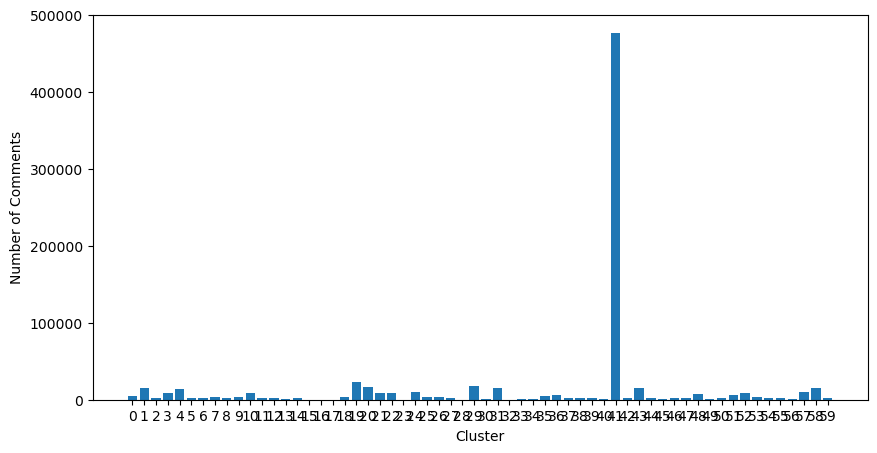

Cluster sizes: 41    476323
19     23206
29     17561
20     16275
1      15774
43     15204
31     15065
58     14994
4      14201
24     10342
57     10122
22      9378
3       9340
52      9336
10      9174
21      8417
48      7181
36      6350
51      6091
35      5270
0       4551
18      3894
7       3847
9       3105
26      3013
25      2974
53      2917
38      2852
39      2842
14      2669
6       2617
5       2468
54      2320
42      2265
11      2257
46      2243
12      2112
55      2105
8       2066
2       1937
59      1922
47      1902
37      1835
44      1773
50      1723
27      1672
56      1343
49      1130
30       799
33       635
13       452
34       401
40       362
45       348
15       250
28       231
17         4
16         2
32         2
23         1
Name: count, dtype: int64


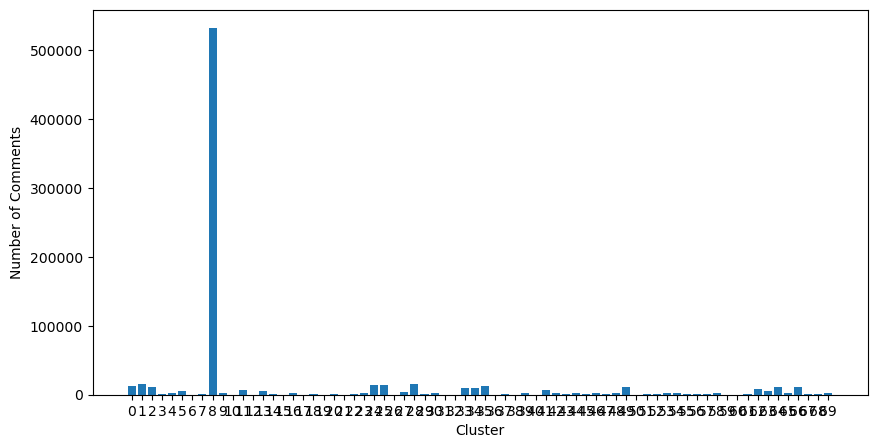

Cluster sizes: 8     531602
1      14861
28     14823
25     13866
24     13671
       ...  
40         1
26         1
38         1
50         1
31         1
Name: count, Length: 70, dtype: int64


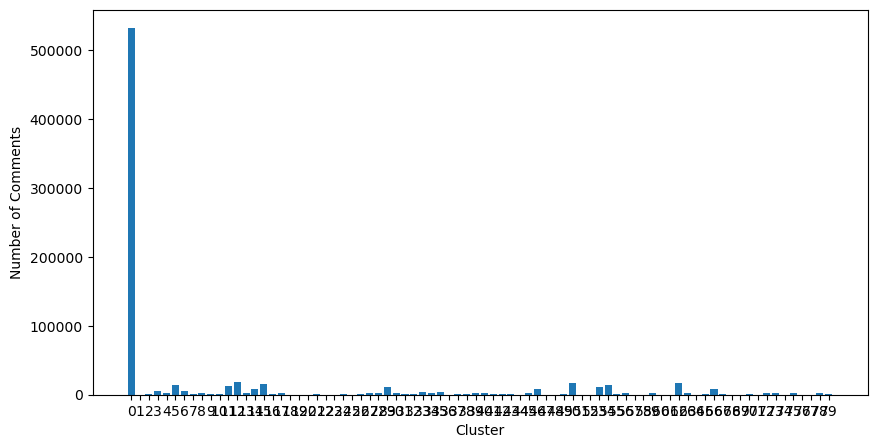

Cluster sizes: 0     532432
12     18670
50     16906
62     16835
15     15599
       ...  
64         1
61         1
71         1
74         1
68         1
Name: count, Length: 80, dtype: int64


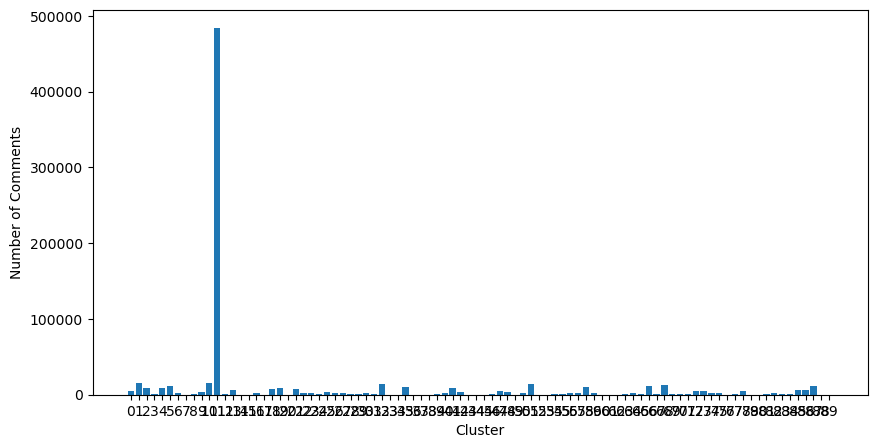

Cluster sizes: 11    483973
1      16022
10     15725
32     14566
51     13975
       ...  
80         1
60         1
38         1
43         1
76         1
Name: count, Length: 90, dtype: int64


In [18]:
#Plot the number of comments for each cluster
for i in clustering_results:
    cluster_sizes = pd.Series(i.labels_).value_counts()
    plt.figure(figsize=(10, 5))
    plt.bar(cluster_sizes.index, cluster_sizes.values)
    #plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Comments")
    plt.xticks(cluster_sizes.index)
    plt.show()
    print("Cluster sizes:", cluster_sizes)

In [ ]:
# from sklearn.cluster import HDBSCAN

# hdbscan_results = []

# hdbscan = HDBSCAN(min_samples=3)
# hdbscan_results=hdbscan.fit(X)

# score = silhouette_score(X, hdbscan_results.labels_,sample_size=10000)

# # compute silhouette score only of clustered samples (not noise, i.e., not -1)
# mask = hdbscan_results.labels_ != -1
# score_No_Outliers = silhouette_score(X[mask], hdbscan_results.labels_[mask],sample_size=n_sample)
# print("Silhouette score:", score)
# print("Silhouette score (clustered samples only):", score_No_Outliers)
# print("Number of outliers detected:", np.sum(hdbscan_results.labels_ == -1))

In [ ]:
# cluster_sizes = pd.Series(hdbscan_results.labels_[mask]).value_counts()
# plt.figure(figsize=(10, 5))
# plt.bar(cluster_sizes.index, cluster_sizes.values)
# plt.title(f"Number of Comments in Each Cluster without outliers")
# plt.xlabel("Cluster")
# plt.ylabel("Number of Comments")
# plt.xticks(cluster_sizes.index)
# plt.show()
# print("Cluster sizes:", cluster_sizes)

In [ ]:
import pickle

with open("kmeans_clustering_results.pkl", "wb") as f:
    pickle.dump(clustering_results, f)

# with open("hdbscan_results.pkl", "wb") as f:
#     pickle.dump(hdbscan_results, f)